# Path finding in a Graph Setting -  First Programming Assignment

Group Number:15

Member 1:Yueting Gou

Member 2:Tiantian Xing

---



This notebook demonstrates **pathfinding algorithms** across three settings:

**Setting 1: Minimum Step Path (Uniform Cost = 1)**
- Objective: Find the **shortest path in terms of steps**.
- Every move costs **1 unit**.
- Include **two** new algorithms for comparison.
- Graph 1 and Graph 2

**Setting 2: Minimum Cost Path (Weighted or Blocked Paths)**
- Objective: Find the **least-cost path** where some paths are **blocked** or have **different traversal costs**.
- Include **two** new algorithms.
- Graph 3 and Graph 4

**Setting 3: Minimum Cost Path (Weighted and Blocked Paths)**
- Objective: Find the **least-cost path** where some paths are **blocked** and have **different traversal costs** in a grid.
- Include **one** algorithm.
- Graph 5

Each section includes explanations of what the code does and what to expect as output.


-----------------------------------------



For **each setting**, you'll first **visualize the graph unsolved**, then **choose the search algorithms** to implement and compare, i.e.:

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;A.  Visualize the graph (unsolved)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;B.  Run **Algorithm 1** (your choice)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;C.  Run **Algorithm 2** (your choice)

&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;D. Compare Performance, Visualise and Show Costs and Steps

You can implement more algorithms and test them if you want, but the least requirement is two algorithms for Setting 1 & 2, and one algorithm for Setting 3. **By the end you should have a total of at least 5 search algorithms.** You can change names, parameters, and return formats as long as you keep `(path, cost, etc)` for comparability.

- Suggested signature: `search_algorithm_ name_objective1(graph, start, goal, blocked=frozenset())`
- Suggested signature: `search_algorithm_name_objective1(graph, start, goal, blocked=frozenset())`

Please be aware that we are looking for algorithms that their functionality matches with each obejctive. So be able to justify your choices!


--------------

## **Preparation**

Here you have a setup required for running this project.

In [43]:
# Setup (safe if already installed)
!pip -q install networkx matplotlib

Here we have provided all the necessary imports, you can also add the libraries that you need for your implementation, please dont delete any of the ones we have provided.

In [44]:
import math
import heapq
import networkx as nx
import matplotlib.pyplot as plt
from typing import FrozenSet, Tuple, Optional, List, Dict
import random

### Helper Functions (single block)
Run this once. It defines utilities for neighbors, path reconstruction, plotting, and a side-by-side comparison plotter.

**PLEASE DO NOT ALTER THE CODE**

In [45]:
def neighbors(graph, node, blocked: FrozenSet[Tuple[str, str]]):
    for nbr, cost in graph.get(node, {}).items():
        e = tuple(sorted((node, nbr)))
        if e in blocked:
            continue
        yield nbr, cost

def reconstruct_path(parent, start, goal):
    if start == goal:
        return [start]
    if goal not in parent:
        return None
    path = [goal]
    cur = goal
    while cur != start:
        cur = parent[cur]
        path.append(cur)
    path.reverse()
    return path

def build_nx_graph(graph, pos):
    G = nx.Graph()
    for n in graph:
        G.add_node(n, pos=pos[n])
    for u, nbrs in graph.items():
        for v, w in nbrs.items():
            if not G.has_edge(u, v):
                G.add_edge(u, v, weight=w)
    return G

def draw_graph_unsolved(graph, pos, start, goal, blocked, title="Graph"):
    G = build_nx_graph(graph, pos)
    plt.figure(figsize=(6, 5))
    nx.draw_networkx_edges(G, pos, edge_color="#cccccc", width=1.5)
    nx.draw_networkx_nodes(G, pos, node_size=550, node_color="#f2f2f2",
                           edgecolors="#444444", linewidths=1.0)
    nx.draw_networkx_labels(G, pos, font_size=10)
    edge_labels = nx.get_edge_attributes(G, "weight")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=9)

    blocked_sorted = {tuple(sorted(e)) for e in blocked}
    for (u, v) in G.edges():
        if tuple(sorted((u, v))) in blocked_sorted:
            nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], width=2.5,
                                   style="dashed", edge_color="#d62728")

    nx.draw_networkx_nodes(G, pos, nodelist=[start], node_shape="s",
                           node_color="#1f77b4", node_size=800, edgecolors="#1f77b4")
    nx.draw_networkx_nodes(G, pos, nodelist=[goal], node_shape="o",
                           node_color="#ff7f0e", node_size=800, edgecolors="#ff7f0e")
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()


def draw_graph(graph, pos, path=None, start=None, goal=None, blocked=frozenset(), title="Graph"):
    G = build_nx_graph(graph, pos)
    plt.figure(figsize=(7, 6))
    nx.draw_networkx_nodes(G, pos, node_size=600, node_color="#f2f2f2", edgecolors="black")
    nx.draw_networkx_labels(G, pos, font_size=10)
    nx.draw_networkx_edges(G, pos, width=1.5, edge_color="#cccccc")
    nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "weight"))

    # Blocked edges (if any)
    for (u, v) in blocked:
        nx.draw_networkx_edges(G, pos, edgelist=[(u, v)], width=3, style="dashed", edge_color="red")

    # Path (if provided)
    if path and len(path) > 1:
        edges = list(zip(path, path[1:]))
        nx.draw_networkx_edges(G, pos, edgelist=edges, width=4, edge_color="green")

    # Start and goal
    if start:
        nx.draw_networkx_nodes(G, pos, nodelist=[start], node_color="blue", node_shape="s", node_size=800)
    if goal:
        nx.draw_networkx_nodes(G, pos, nodelist=[goal], node_color="orange", node_shape="o", node_size=800)

    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

def normalize_blocked(blocked):
    out = set()
    for e in blocked:
        if isinstance(e, tuple) and len(e) == 2:
            out.add(tuple(sorted(e)))
        elif isinstance(e, (list, set)) and len(e) == 2:
            u, v = sorted(list(e))
            out.add((u, v))
    return frozenset(out)


## **Setting 1.1: Simple (unit-cost) - Graph 1**
**Data**

This code creates the graphs and other variables that **you might need to use** depending on your implementation:

This code defines the setup for Graph 1 (G1):

*   G1 – the graph showing connections between nodes and their edge costs.
*   POS1 – coordinates of each node (for visualization or heuristics).
*   START1 – the starting node ('S').
*   GOAL1 – the goal node ('T').
*   BLOCKED1 – blocked nodes (none in this case).

**PLEASE DO NOT ALTER THE CODE BELOW**

In [46]:
G1 = {
    'S': {'A': 1, 'B': 1},
    'A': {'S': 1, 'C': 1, 'D': 1},
    'B': {'S': 1, 'D': 1, 'E': 1},
    'C': {'A': 1, 'F': 1},
    'D': {'A': 1, 'B': 1, 'F': 1, 'G': 1},
    'E': {'B': 1, 'G': 1, 'H': 1},
    'F': {'C': 1, 'D': 1, 'I': 1},
    'G': {'D': 1, 'E': 1, 'I': 1, 'J': 1},
    'H': {'E': 1, 'J': 1},
    'I': {'F': 1, 'G': 1, 'K': 1},
    'J': {'G': 1, 'H': 1, 'K': 1, 'L': 1},
    'K': {'I': 1, 'J': 1, 'T': 1},
    'L': {'J': 1, 'T': 1},
    'T': {'K': 1, 'L': 1}
}

POS1 = {
    'S': (0, 0), 'A': (1, 1), 'B': (1, -1), 'C': (2, 2), 'D': (2, 0), 'E': (2, -2),
    'F': (3, 1), 'G': (3, -1), 'H': (3, -3), 'I': (4, 1), 'J': (4, -1), 'K': (5, 0),
    'L': (5, -2), 'T': (6, -1)
}

START1, GOAL1 = 'S', 'T'
BLOCKED1 = frozenset()

### A) Visualize Graph (unsolved)

**PLEASE DO NOT ALTER THE CODE BELOW**

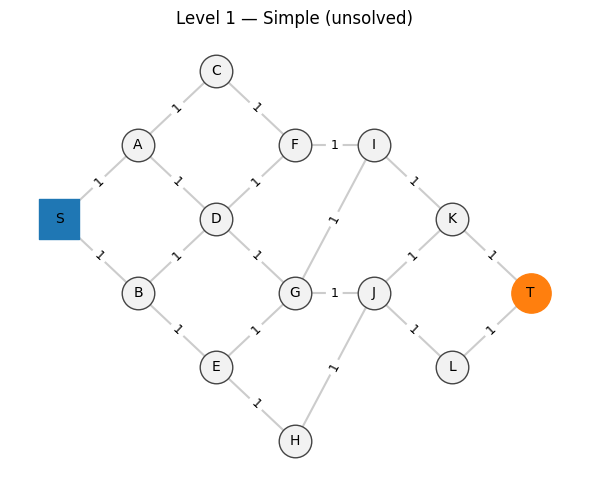

In [47]:
draw_graph_unsolved(G1, POS1, START1, GOAL1, BLOCKED1, title="Level 1 — Simple (unsolved)")

### B) Implement and Run Algorithm 1

Enter **YOUR implementation** of the first selected search algorithm, it must return the **path list of node names (in the visiting order)** and the number of **search steps** as an integer and the **length of the final path**! The algorithm should search for the minimum step path.

Feel free to use helper functions or change formats

In [48]:
def search_1_min_path(graph, start, goal, pos, blocked=frozenset()):
    from collections import deque
    frontier = deque()
    frontier.append(start)
    visited = set()
    visited.add(start)
    parent = {}
    total_search_steps =0

# BFS loop
    while frontier:
        current = frontier.popleft()
        total_search_steps += 1
        if current == goal:
            path = reconstruct_path(parent, start, goal)
            length_final_path = len(path) - 1
            return path, total_search_steps, length_final_path

        for nbr, cost in neighbors(graph, current, blocked):
            if nbr not in visited:
                visited.add(nbr)
                parent[nbr] = current
                frontier.append(nbr)

    return None, total_search_steps, float("inf") # If the goal is not reachable

Here you can run your code, feel free to change the call of the function, inputs and outputs!

In [49]:
path1, search_steps1, length_final_path1 = search_1_min_path(G1, START1, GOAL1, POS1, BLOCKED1)

### C) Implement and Run Algorithm 2

Enter **YOUR implementation** of the second selected search algorithm, it must return the **path list of node names (in the visiting order)** and the number of **search steps** as an integer and the **length of the final path**! The algorithm should search for the minimum step path.

Feel free to use helper functions or change formats

In [50]:
def search_2_min_path(graph, start, goal, pos, blocked=frozenset()):
    frontier = []
    heapq.heappush(frontier, (0, start))
    dist = {start: 0}
    parent = {}
    visited = set()
    total_search_steps = 0
# UCS loop
    while frontier:
        cost_so_far, current = heapq.heappop(frontier)
        if current in visited:
            continue
        visited.add(current)
        total_search_steps += 1
        if current == goal:
            path = reconstruct_path(parent, start, goal)
            length_final_path = len(path) - 1
            return path, total_search_steps, length_final_path

        for nbr, w in neighbors(graph, current, blocked):
            new_cost = cost_so_far + w
            if nbr not in dist or new_cost < dist[nbr]:
                dist[nbr] = new_cost
                parent[nbr] = current
                heapq.heappush(frontier, (new_cost, nbr))

    return None, total_search_steps, float("inf")

Implement and Run Algorithm 3 （DFS)

In [51]:
def search_3_min_path(graph, start, goal, pos, blocked=frozenset()):
    blocked = normalize_blocked(blocked)
    stack = [(start, None)]
    visited = set()
    parent = {}
    search_steps = 0
    while stack:
        current, p = stack.pop()
        search_steps += 1
        if current not in visited:
            visited.add(current)
            if p is not None:
                parent[current] = p
            if current == goal:
                path = reconstruct_path(parent, start, goal)
                return path, search_steps, len(path) - 1
            nbrs = sorted(list(neighbors(graph, current, blocked)), key=lambda x: x[0], reverse=True)

            for nbr, cost in nbrs:
                if nbr not in visited:
                    stack.append((nbr, current))

    return None, search_steps, None

Here you can run your code, feel free to change the call of the function, inputs and outputs!

In [52]:
path2, search_steps2, length_final_path2 = search_2_min_path(G1, START1, GOAL1, POS1, BLOCKED1)


In [53]:
path3, search_steps3, length_final_path3 = search_3_min_path(G1, START1, GOAL1, POS1, BLOCKED1)


### D) Compare Algorithms

Show results of Algorithm 1 for Graph 1

Path: ['S', 'A', 'C', 'F', 'I', 'K', 'T']
Total search steps: 14
Length of final path: 6


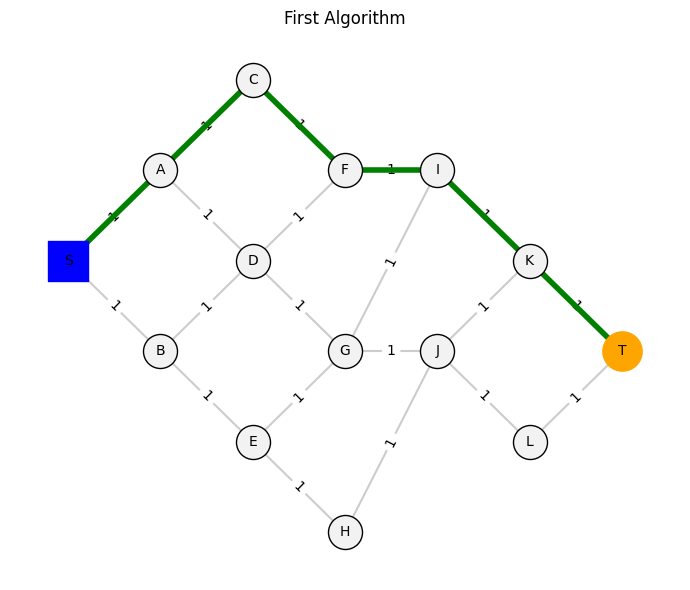

In [54]:
print(f"Path: {path1}")
print(f"Total search steps: {search_steps1}")
print(f"Length of final path: {length_final_path1}")
draw_graph(G1, POS1, path1, START1, GOAL1, BLOCKED1, title="First Algorithm")

Show results of Algorithm 2 for Graph 1

Path: ['S', 'A', 'C', 'F', 'I', 'K', 'T']
Total search steps: 14
Length of final path: 6


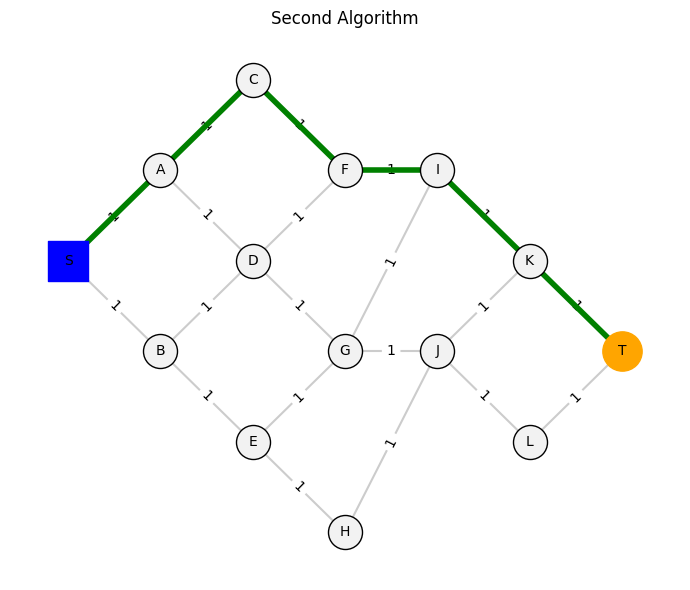

In [55]:
print(f"Path: {path2}")
print(f"Total search steps: {search_steps2}")
print(f"Length of final path: {length_final_path2}")
draw_graph(G1, POS1, path2, START1, GOAL1, BLOCKED1, title="Second Algorithm")

Show results of Algorithm 3 for Graph 1

Path: ['S', 'A', 'C', 'F', 'D', 'B', 'E', 'G', 'I', 'K', 'J', 'L', 'T']
Total search steps: 14
Length of final path: 12


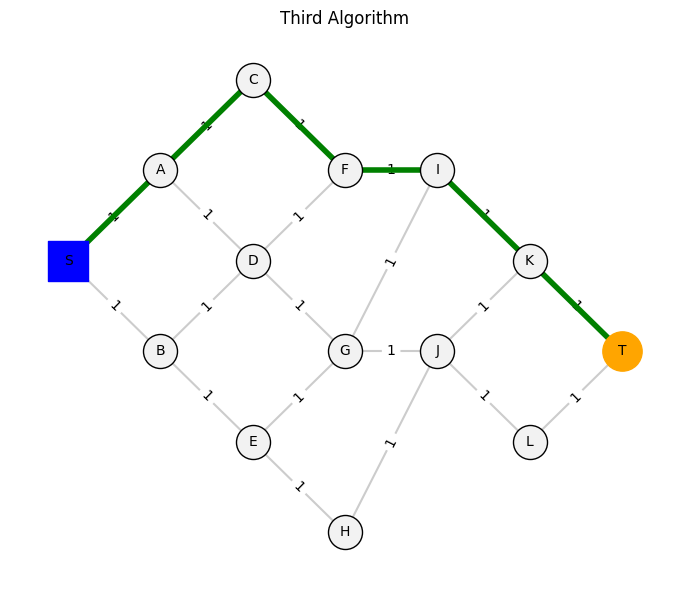

In [56]:
print(f"Path: {path3}")
print(f"Total search steps: {search_steps3}")
print(f"Length of final path: {length_final_path3}")
draw_graph(G1, POS1, path1, START1, GOAL1, BLOCKED1, title="Third Algorithm")

## **Setting 1.2: Simple (unit-cost) - Graph 2**

**This is a more complex graph where all the steps have a uniform cost of 1, you are still searching for minimum number of steps**


This code creates the graphs and other variables that **you might need to use** depending on your implementation:

This code defines the setup for Graph 1 (G1):

*   G2 – the graph showing connections between nodes and their edge costs.
*   POS2 – coordinates of each node (for visualization or heuristics).
*   START2 – the starting node ('S').
*   GOAL2 – the goal node ('T').
*   BLOCKED2 – blocked nodes (none in this case).

**PLEASE DO NOT ALTER THE CODE BELOW**

In [57]:
G2 = {
    'S': {'A': 1, 'B': 1, 'C': 1},
    'A': {'S': 1, 'D': 1, 'E': 1},
    'B': {'S': 1, 'E': 1, 'F': 1},
    'C': {'S': 1, 'F': 1, 'G': 1},
    'D': {'A': 1, 'H': 1, 'I': 1},
    'E': {'A': 1, 'B': 1, 'I': 1, 'J': 1},
    'F': {'B': 1, 'C': 1, 'J': 1, 'K': 1},
    'G': {'C': 1, 'K': 1, 'L': 1},
    'H': {'D': 1, 'M': 1},
    'I': {'D': 1, 'E': 1, 'M': 1, 'N': 1},
    'J': {'E': 1, 'F': 1, 'N': 1, 'O': 1},
    'K': {'F': 1, 'G': 1, 'O': 1, 'P': 1},
    'L': {'G': 1, 'P': 1, 'Q': 1},
    'M': {'H': 1, 'I': 1, 'R': 1},
    'N': {'I': 1, 'J': 1, 'R': 1, 'S2': 1},
    'O': {'J': 1, 'K': 1, 'S2': 1, 'T': 1},
    'P': {'K': 1, 'L': 1, 'T': 1},
    'Q': {'L': 1, 'T': 1},
    'R': {'M': 1, 'N': 1, 'S2': 1},
    'S2': {'N': 1, 'O': 1, 'R': 1, 'T': 1},
    'T': {'O': 1, 'P': 1, 'Q': 1, 'S2': 1}
}
POS2 = {
    'S': (0, 0),
    'A': (1, 1), 'B': (1, 0), 'C': (1, -1),
    'D': (2, 2), 'E': (2, 1), 'F': (2, -1), 'G': (2, -2),
    'H': (3, 2), 'I': (3, 1), 'J': (3, -1), 'K': (3, -2), 'L': (3, -3),
    'M': (4, 2), 'N': (4, 1), 'O': (4, -1), 'P': (4, -2), 'Q': (4, -3),
    'R': (5, 1), 'S2': (5, 0), 'T': (6, -1)
}
START2, GOAL2 = 'S', 'T'
BLOCKED2 = frozenset()


### A) Visualize Graph (unsolved)

**PLEASE DO NOT ALTER THE CODE BELOW**

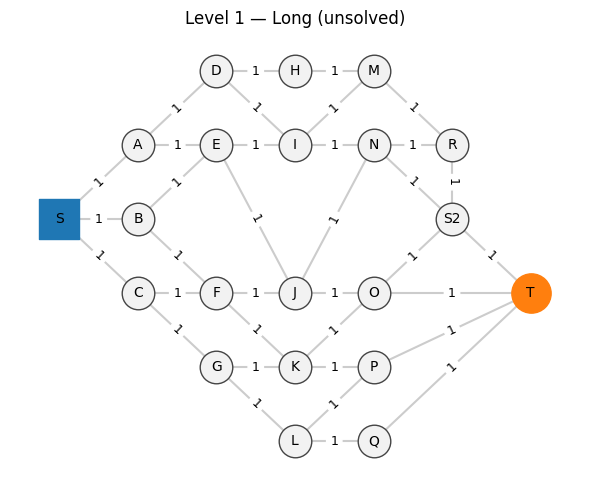

In [58]:
draw_graph_unsolved(G2, POS2, START2, GOAL2, BLOCKED2, title="Level 1 — Long (unsolved)")

### B) Run Algorithm 1 for Graph2

Here you can run your code, feel free to change the call of the function, inputs and outputs!

In [59]:
path1_2, search_steps1_2, length_final_path1_2 = search_1_min_path(G2, START2, GOAL2, POS2, BLOCKED2)

### C) Implement and Run Algorithm 2 & 3

Here you can run your code, feel free to change the call of the function, inputs and outputs!

In [60]:
path2_2, search_steps2_2, length_final_path2_2 = search_2_min_path(G2, START2, GOAL2, POS2, BLOCKED2)

In [61]:
path3_2, search_steps3_2, length_final_path3_2 = search_3_min_path(G2, START2, GOAL2, POS2, BLOCKED2)

### D) Compare Algorithms

Show results of Algorithm 1 for Graph 2

Path: ['S', 'A', 'E', 'J', 'O', 'T']
Total search steps: 21
Length of final path: 5


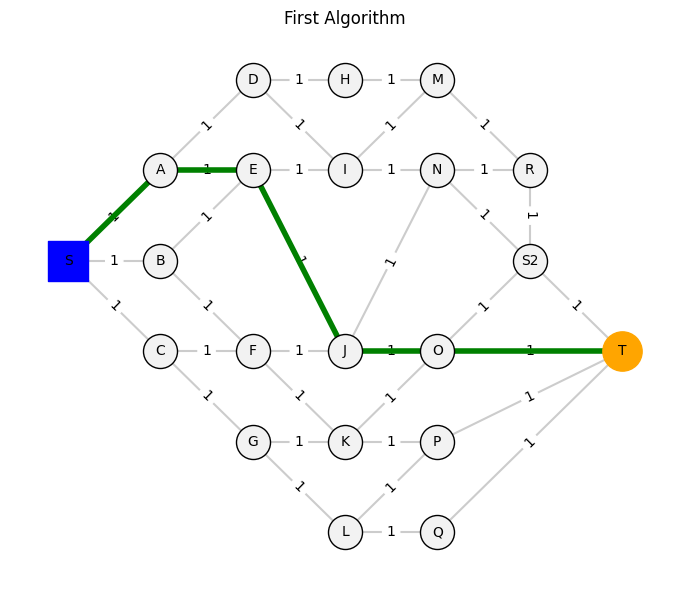

In [62]:
print(f"Path: {path1_2}")
print(f"Total search steps: {search_steps1_2}")
print(f"Length of final path: {length_final_path1_2}")
draw_graph(G2, POS2, path1_2, START2, GOAL2, BLOCKED2, title="First Algorithm")

Show results of Algorithm 2 for Graph 2

Path: ['S', 'A', 'E', 'J', 'O', 'T']
Total search steps: 21
Length of final path: 5


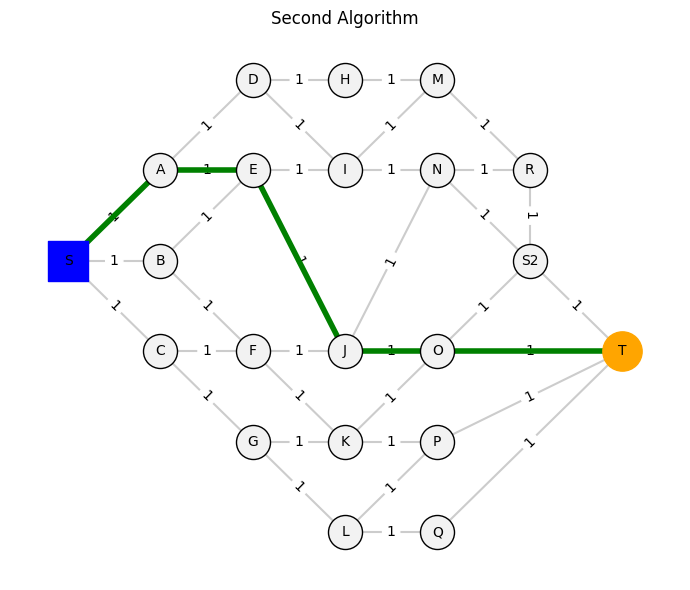

In [63]:
print(f"Path: {path2_2}")
print(f"Total search steps: {search_steps2_2}")
print(f"Length of final path: {length_final_path2_2}")
draw_graph(G2, POS2, path2_2, START2, GOAL2, BLOCKED2, title="Second Algorithm")

Show results of Algorithm 3 for Graph 2

Path: ['S', 'A', 'D', 'H', 'M', 'I', 'E', 'B', 'F', 'C', 'G', 'K', 'O', 'J', 'N', 'R', 'S2', 'T']
Total search steps: 18
Length of final path: 17


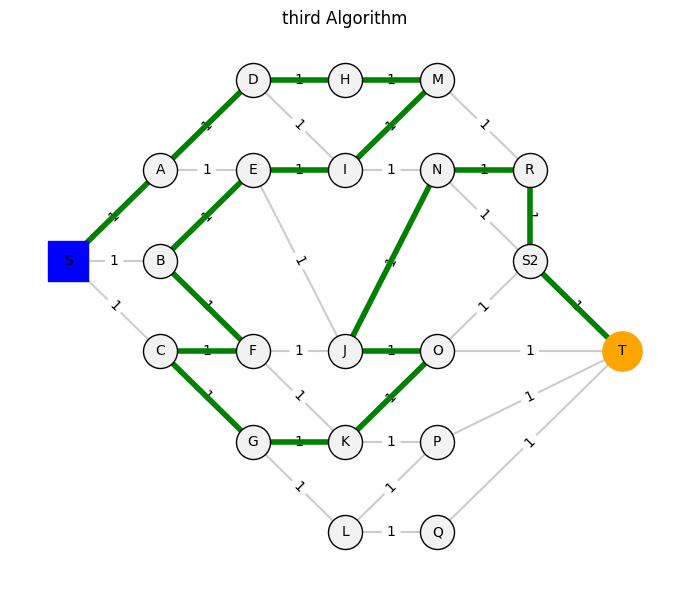

In [64]:
print(f"Path: {path3_2}")
print(f"Total search steps: {search_steps3_2}")
print(f"Length of final path: {length_final_path3_2}")
draw_graph(G2, POS2, path3_2, START2, GOAL2, BLOCKED2, title="third Algorithm")

## **Setting 2.1: Simple (weighted-edges) graph - Graph 3**
**Data**

This code creates the graphs and other variables that **you might need to use** depending on your implementation:

This code defines the setup for Graph 3 (G3):

*   G3 – the graph showing connections between nodes and their edge costs.
*   POS3 – coordinates of each node (for visualization or heuristics).
*   START3 – the starting node ('S').
*   GOAL3 – the goal node ('T').
*   BLOCKED3 – blocked nodes (YES in this case).

**PLEASE DO NOT ALTER THE CODE BELOW**

In [65]:
import itertools
G_grid={(x,y):{} for x,y in itertools.product(range(5),range(5))}
for x,y in list(G_grid.keys()):
    for dx,dy in [(1,0),(0,1)]:
        nx_,ny_=x+dx,y+dy
        if (nx_,ny_) in G_grid: G_grid[(x,y)][(nx_,ny_)]=1; G_grid[(nx_,ny_)][(x,y)]=1
BLOCKED_EDGES={((1,1),(1,2)),((2,2),(3,2)),((3,3),(4,3))}
POS_grid={(x,y):(x,-y) for x,y in G_grid}
START,GOAL=(0,0),(4,4); BLOCKED=normalize_blocked(BLOCKED_EDGES)

G3=G_grid
POS3=POS_grid
START3=START
GOAL3=GOAL
BLOCKED3=BLOCKED


### A) Visualize Graph (unsolved)

**PLEASE DO NOT ALTER THE CODE BELOW**

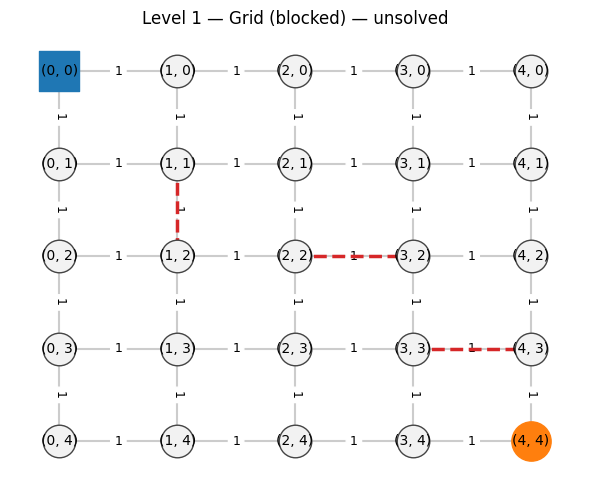

In [66]:
draw_graph_unsolved(G3, POS3, START3, GOAL3, BLOCKED3, title="Level 1 — Grid (blocked) — unsolved")


### B) Implement and Run Algorithm 1

Enter **YOUR implementation** of the first selected search algorithm, it must return the **path list of node names (in the visiting order)** and the number of **search steps** as an integer and the **cost of the final path**! The algorithm should search for the **minimum cost path**.

Feel free to use helper functions or change formats

In [67]:
def search_1_min_cost(graph, start, goal, pos, blocked=frozenset()):
    frontier = []
    heapq.heappush(frontier, (0, start)) # Start from the initial node with cost 0
    dist = {start: 0}
    parent = {}
    visited = set()
    total_search_steps = 0
# UCS loop
    while frontier:
        current_cost, current = heapq.heappop(frontier)
        if current in visited:
            continue
        visited.add(current)
        total_search_steps += 1
        if current == goal:
            path = reconstruct_path(parent, start, goal)
            total_cost = dist[goal]
            return path, total_cost, total_search_steps

        for nbr, edge_cost in neighbors(graph, current, blocked):
            new_cost = current_cost + edge_cost
            if nbr not in dist or new_cost < dist[nbr]:
                dist[nbr] = new_cost
                parent[nbr] = current
                heapq.heappush(frontier, (new_cost, nbr))

    return None, float("inf"), total_search_steps

Here you can run your code, feel free to change the call of the function, inputs and outputs!

In [68]:
path1_3, search_steps1_3, cost_final_path1_3 = search_1_min_cost(G3, START3, GOAL3, POS3, BLOCKED3)

### C) Implement and Run Algorithm 2

Enter **YOUR implementation** of the first selected search algorithm, it must return the **path list of node names (in the visiting order)** and the number of **search steps** as an integer and the **cost of the final path**! The algorithm should search for the **minimum cost path**.

Feel free to use helper functions or change formats

In [69]:
def search_2_min_cost(graph, start, goal, pos, blocked=frozenset()):
    def heuristic(n):
        (x1, y1) = pos[n]
        (x2, y2) = pos[goal]
        return math.hypot(x1 - x2, y1 - y2)

    frontier = []
    heapq.heappush(frontier, (heuristic(start), 0, start))
    g_cost = {start: 0}
    parent = {}
    visited = set()
    total_search_steps = 0
# A* search loop
    while frontier:
        f, current_g, current = heapq.heappop(frontier)
        if current in visited:
            continue
        visited.add(current)
        total_search_steps += 1
        if current == goal:
            path = reconstruct_path(parent, start, goal)
            total_cost = g_cost[goal]
            return path, total_cost, total_search_steps

        for nbr, edge_cost in neighbors(graph, current, blocked):
            tentative_g = current_g + edge_cost
            if nbr not in g_cost or tentative_g < g_cost[nbr]:
                g_cost[nbr] = tentative_g
                parent[nbr] = current
                f_new = tentative_g + heuristic(nbr)
                heapq.heappush(frontier, (f_new, tentative_g, nbr))

    return None, float("inf"), total_search_steps

Here you can run your code, feel free to change the call of the function, inputs and outputs!

In [70]:
path2_3, search_steps2_3, cost_final_path2_3 = search_2_min_cost(G3, START3, GOAL3, POS3, BLOCKED3)

### D) Compare Algorithms

Show results of Algorithm 1 for Graph 3

Path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (3, 4), (4, 4)]
Total search steps: 8
Cost of final path: 25


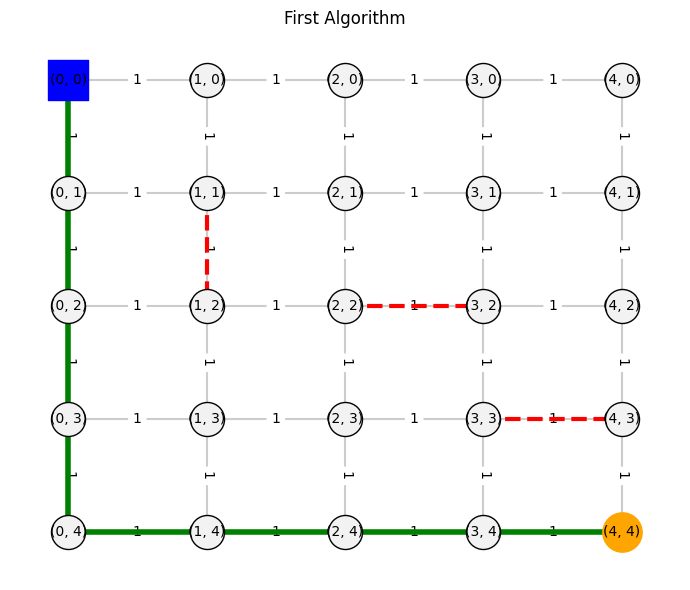

In [71]:
print(f"Path: {path1_3}")
print(f"Total search steps: {search_steps1_3}")
print(f"Cost of final path: {cost_final_path1_3}")
draw_graph(G3, POS3, path1_3, START3, GOAL3, BLOCKED3, title="First Algorithm")

Show results of Algorithm 2 for Graph 3

Path: [(0, 0), (0, 1), (0, 2), (1, 2), (2, 2), (2, 3), (3, 3), (3, 4), (4, 4)]
Total search steps: 8
Cost of final path: 25


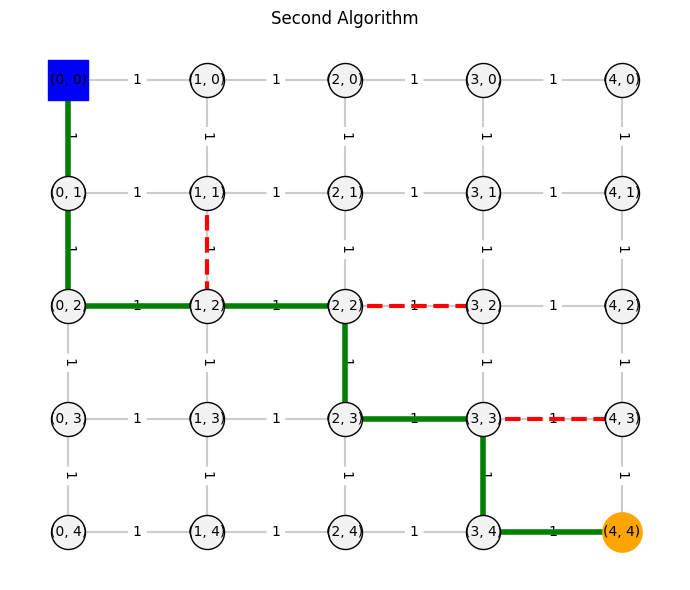

In [72]:
print(f"Path: {path2_3}")
print(f"Total search steps: {search_steps2_3}")
print(f"Cost of final path: {cost_final_path2_3}")
draw_graph(G3, POS3, path2_3, START3, GOAL3, BLOCKED3, title="Second Algorithm")

## **Setting 2.2: Simple (weighted-edges) graph - Graph 4**
**Data**

This code creates the graphs and other variables that **you might need to use** depending on your implementation:

This code defines the setup for Graph 4 (G4):

*   G4 – the graph showing connections between nodes and their edge costs.
*   POS4 – coordinates of each node (for visualization or heuristics).
*   START4 – the starting node ('S').
*   GOAL4 – the goal node ('T').
*   BLOCKED4 – blocked nodes (No in this case).

**PLEASE DO NOT ALTER THE CODE BELOW**

In [73]:
G4 = {
    'S': {'A': 2, 'B': 3},
    'A': {'S': 2, 'C': 2, 'D': 3},
    'B': {'S': 3, 'D': 1, 'E': 4},
    'C': {'A': 2, 'F': 3, 'G': 5},
    'D': {'A': 3, 'B': 1, 'F': 2, 'G': 2, 'H': 4},
    'E': {'B': 4, 'H': 1, 'I': 3},
    'F': {'C': 3, 'D': 2, 'J': 4, 'K': 5},
    'G': {'C': 5, 'D': 2, 'K': 3, 'L': 4},
    'H': {'D': 4, 'E': 1, 'L': 2, 'M': 3},
    'I': {'E': 3, 'M': 2, 'N': 4},
    'J': {'F': 4, 'K': 1, 'O': 3},
    'K': {'F': 5, 'G': 3, 'J': 1, 'L': 2, 'O': 2, 'P': 4},
    'L': {'G': 4, 'H': 2, 'K': 2, 'P': 3, 'Q': 5},
    'M': {'H': 3, 'I': 2, 'Q': 3, 'R': 4},
    'N': {'I': 4, 'R': 2},
    'O': {'J': 3, 'K': 2, 'P': 1, 'S2': 5},
    'P': {'K': 4, 'L': 3, 'O': 1, 'Q': 2, 'S2': 4},
    'Q': {'L': 5, 'M': 3, 'P': 2, 'R': 2, 'T': 5},
    'R': {'M': 4, 'N': 2, 'Q': 2, 'T': 3},
    'S2': {'O': 5, 'P': 4, 'T': 6},
    'T': {'Q': 5, 'R': 3, 'S2': 6}
}
POS4 = {
    'S': (0, 0), 'A': (1, 1), 'B': (1, -1),
    'C': (2, 2), 'D': (2, 0), 'E': (2, -2),
    'F': (3, 1), 'G': (3, -1), 'H': (3, -3),
    'I': (3, -4), 'J': (4, 2), 'K': (4, 0),
    'L': (4, -2), 'M': (4, -4), 'N': (4, -6),
    'O': (5, 1), 'P': (5, -1), 'Q': (5, -3),
    'R': (5, -5), 'S2': (6, 0), 'T': (7, -2)
}
START4, GOAL4 = 'S', 'T'
BLOCKED4 = frozenset()  # optional — you can add more to simulate obstacles


### A) Visualize Graph (unsolved)

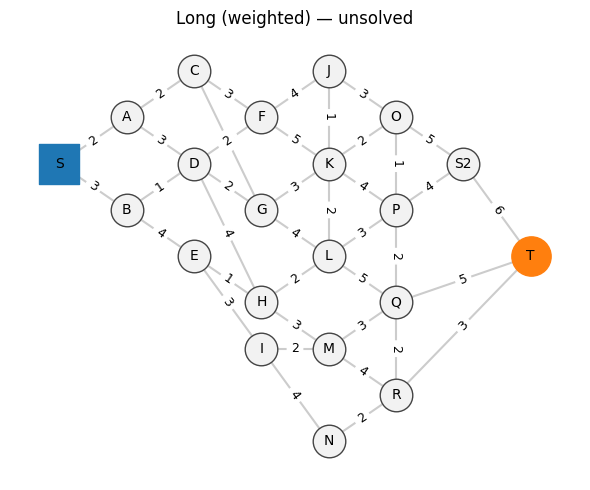

In [74]:
draw_graph_unsolved(G4, POS4, START4, GOAL4, BLOCKED4, title="Long (weighted) — unsolved")

### B) Run Algorithm 1

In [75]:
path1_4, search_steps1_4, cost_final_path1_4 = search_1_min_cost(G4, START4, GOAL4, POS4, BLOCKED4)

### C) Run Algorithm 2

In [76]:
path2_4, search_steps2_4, cost_final_path2_4 = search_2_min_cost(G4, START4, GOAL4, POS4, BLOCKED4)

### D) Compare Algorithms

Show results of Algorithm 1 for Graph 4

Path: ['S', 'B', 'D', 'H', 'M', 'R', 'T']
Total search steps: 18
Cost of final path: 21


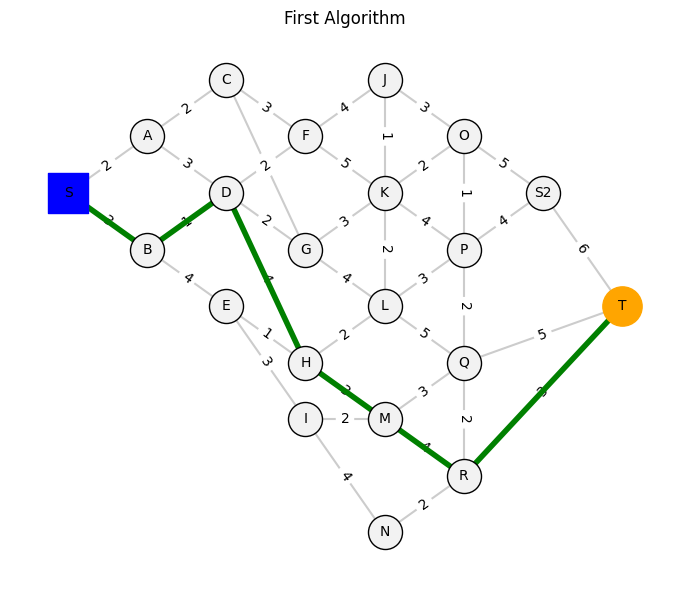

In [77]:
print(f"Path: {path1_4}")
print(f"Total search steps: {search_steps1_4}")
print(f"Cost of final path: {cost_final_path1_4}")
draw_graph(G4, POS4, path1_4, START4, GOAL4, BLOCKED4, title="First Algorithm")

Show results of Algorithm 2 for Graph 4

Path: ['S', 'B', 'D', 'H', 'M', 'R', 'T']
Total search steps: 18
Cost of final path: 20


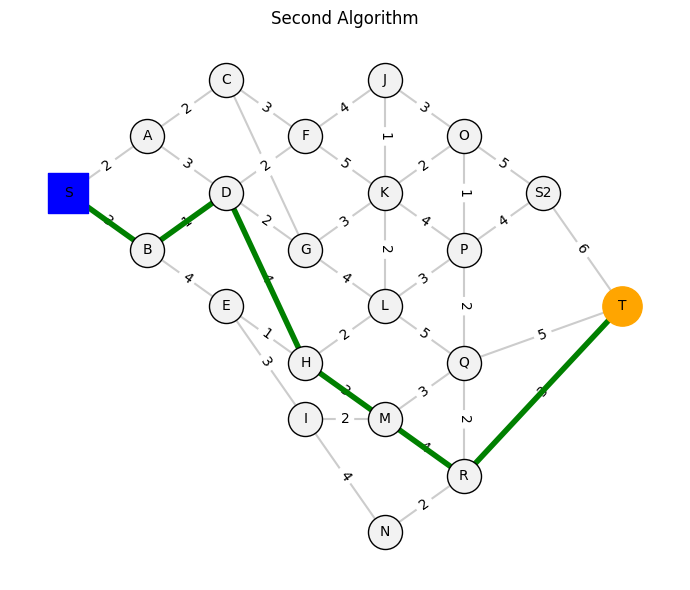

In [78]:
print(f"Path: {path2_4}")
print(f"Total search steps: {search_steps2_4}")
print(f"Cost of final path: {cost_final_path2_4}")
draw_graph(G4, POS4, path2_4, START4, GOAL4, BLOCKED4, title="Second Algorithm")

## **Setting 3.1: Weighted and Blocked Grid - Graph 5**

### Final Exercise: Penalty and Weight Sensitivity in Grid City

You are given a weighted grid graph representing a small city map, where each node corresponds to an intersection and each edge represents a road with an associated travel cost. Some edges are highlighted in red, indicating that they are dangerous or blocked. These dangerous edges are typically shorter and have a lower base cost, but using them may incur an additional penalty.

Your task is to find a path from the START to the GOAL node that balances efficiency and safety. While shorter routes may seem optimal, they could include risky edges that increase the overall cost once penalties are applied. Consider how to adapt or extend a shortest-path algorithm (e.g., Dijkstra or A*) to account for both the edge weights and the penalties of dangerous roads.



Once Again:

*   G5 – the graph showing connections between nodes and their edge costs.
*   POS5 – coordinates of each node (for visualization or heuristics).
*   START5 – the starting node ('S').
*   GOAL5 – the goal node ('T').
*   BLOCKED5 – blocked nodes (YES in this case).


In [79]:
# 🧮 Grid City (weighted)
# !!! DO NOT CHANGE THIS CODE !!!
G_wgrid={(x,y):{} for x,y in itertools.product(range(5),range(5))}
random.seed(1)
for x,y in list(G_wgrid.keys()):
    for dx,dy in [(1,0),(0,1)]:
        nx_,ny_=x+dx,y+dy
        if (nx_,ny_) in G_wgrid:
            w=random.randint(1,9)
            G_wgrid[(x,y)][(nx_,ny_)]=w; G_wgrid[(nx_,ny_)][(x,y)]=w
for i in range(4):
    for j in range(4):
        if (i+j)%2==0:
            G_wgrid[(i,j)][(i+1,j+1)]=random.randint(2,9)
            G_wgrid[(i+1,j+1)][(i,j)]=G_wgrid[(i,j)][(i+1,j+1)]
POS_wgrid={(x,y):(x,-y) for x,y in G_wgrid}
START,GOAL=(0,0),(4,4); BLOCKED=frozenset()
BLOCKED_EDGES={((1,1),(1,2)),((2,2),(3,2)),((3,3),(4,3)), ((4, 3), (4, 4))}
BLOCKED=normalize_blocked(BLOCKED_EDGES)
G_wgrid[(3, 2)][(3, 3)] = 1
G_wgrid[(3, 3)][(3, 2)] = 1

G_wgrid[(1, 1)][(1, 2)] = 0
G_wgrid[(1, 2)][(1, 1)] = 0

G_wgrid[(1, 2)][(2, 2)] = 2
G_wgrid[(2, 2)][(1, 2)] = 2

G_wgrid[(1, 3)][(2, 3)] = 2
G_wgrid[(2, 3)][(1, 3)] = 2

G_wgrid[(1, 4)][(2, 4)] = 2
G_wgrid[(2, 4)][(1, 4)] = 2

G_wgrid[(3, 3)][(4, 3)] = 4
G_wgrid[(4, 3)][(3, 3)] = 4

G_wgrid[(4, 3)][(4, 4)] = 5
G_wgrid[(4, 4)][(4, 3)] = 5

G_wgrid[(3, 3)][(4, 4)] = 15
G_wgrid[(4, 4)][(3, 3)] = 15

G5=G_wgrid
POS5=POS_wgrid
START5=START
GOAL5=GOAL
BLOCKED5=BLOCKED

# !!! DO NOT CHANGE THIS CODE !!!

### A) Visualize Graph (unsolved)

**PLEASE DO NOT ALTER THE CODE BELOW**

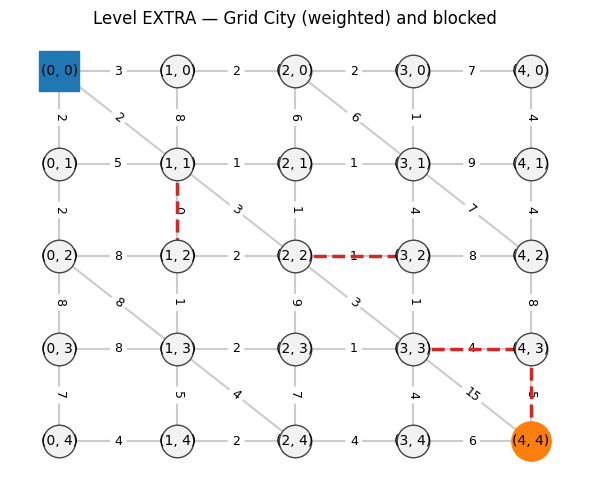

In [80]:
draw_graph_unsolved(G5,POS5,START5,GOAL5,BLOCKED5,'Level EXTRA — Grid City (weighted) and blocked')

### B) Implement and Run Algorithm

Enter **YOUR implementation** of the  selected search algorithm, it must return the **path list of node names (in the visiting order)** and the number of **search steps** as an integer and the **cost of the final path**! The algorithm should search for the **minimum cost path**.

Feel free to use helper functions or change formats.

#### **In this case, you can either modify one of the algorithms of setting 2, or implement a new one!**

 Implement Your Search Algorithm

In the next cell, you are asked to complete the search routine based on the provided template.  
The search should expand nodes in order of increasing total cost and maintain the best-known cost to each visited node.  
Some edges are marked as **blocked/dangerous**. For such edges, you must either **skip** them completely (`mode="forbid"`) or **penalize** them (`mode="penalize"`) by adding an extra term to the edge cost.  

The effective edge cost in the penalized case is:

```
effective_cost = graph_cost + (weight * penalty)
```


Your implementation should ideally:
1. Compute this effective cost when needed.  
2. Update the cumulative cost to the neighbor if the new path is cheaper.  
3. Update the parent pointer accordingly.  
4. Push the neighbor into the priority queue.  

This allows you to compare paths that use risky edges with those that avoid them.

In [81]:
def search_3_min_cost(graph, start, goal, pos, blocked=frozenset()):
    mode    = "penalize"
    penalty = 5
    weight  = 0.2
    def heuristic(n):
        x1, y1 = pos[n]
        x2, y2 = pos[goal]
        return math.hypot(x1 - x2, y1 - y2)

    frontier = []
    heapq.heappush(frontier, (heuristic(start), 0, start))
    g_cost = {start: 0}
    parent = {}
    visited = set()
    total_search_steps = 0
    risky_edges = {tuple(sorted(e)) for e in blocked}
# A* search loop
    while frontier:
        f, current_g, current = heapq.heappop(frontier)
        total_search_steps += 1
        if current_g > g_cost[current]:
            continue
        if current == goal:
            path = reconstruct_path(parent, start, goal)
            return path, g_cost[goal], total_search_steps, mode, penalty, weight

        for nbr, base_cost in graph.get(current, {}).items():
            e = tuple(sorted((current, nbr)))
            is_risky = e in risky_edges
            if mode == "forbid" and is_risky:
                continue
            effective_cost = base_cost
            if mode == "penalize" and is_risky:
                effective_cost = base_cost + weight * penalty
            tentative_g = current_g + effective_cost
            if tentative_g < g_cost.get(nbr, float("inf")):
                g_cost[nbr] = tentative_g
                parent[nbr] = current
                f_new = tentative_g + heuristic(nbr)
                heapq.heappush(frontier, (f_new, tentative_g, nbr))

    return None, float("inf"), total_search_steps, mode, penalty, weight

Here you can run your code, feel free to change the call of the function, inputs and outputs!

In [82]:
path3, search_steps3, cost_final_path3, mode, penalty, weight = search_3_min_cost(
    G5, START5, GOAL5, POS5, BLOCKED5)

### C) Experiment

In the next cell, you are going to run your implementation of the search algorithm.  
Try experimenting with **different values of `weight` and `penalty`** to observe how the resulting path changes.  
Observe how the balance between **cost efficiency** and **safety** shifts as you adjust these parameters. Showcase it in your presentation!

In [83]:
path3, cost_final_path3, search_steps3, mode, penalty, weight = search_3_min_cost(G5, START5, GOAL5, POS5, BLOCKED5)

Show results of Algorithm 3 for Graph 5

Path: [(0, 0), (1, 1), (2, 1), (2, 2), (3, 3), (3, 4), (4, 4)]
Total search steps: 29
Cost of final path: 17
Mode: penalize
Penalty: 5
Weight: 0.2


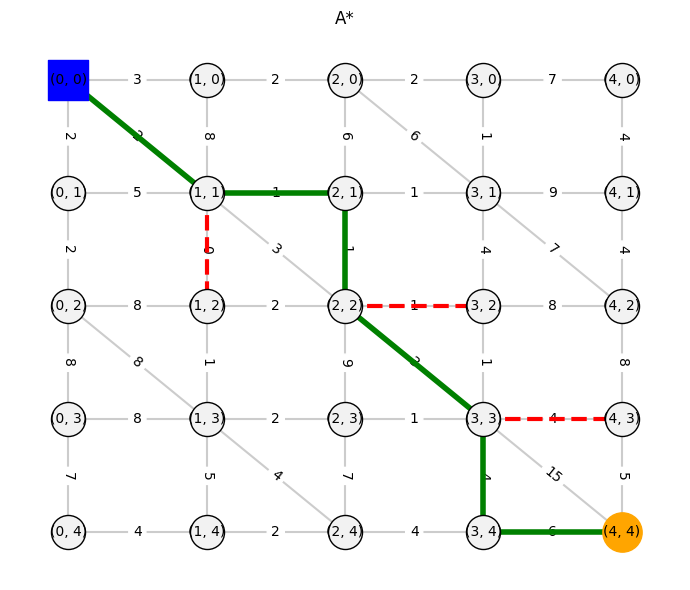

In [84]:
print(f"Path: {path3}")
print(f"Total search steps: {search_steps3}")
print(f"Cost of final path: {cost_final_path3}")
print(f"Mode: {mode}")
print(f"Penalty: {penalty}")
print(f"Weight: {weight}")
draw_graph(G5, POS3, path3, START3, GOAL3, BLOCKED3, title="A*")

### ❓ Question

What would be the **minimum and maximum values** for both `penalty` and `weight` such that the path considering dangerous edges has always a lower cost than the one avoiding these edges?  

In the penalized mode, the effective edge cost is defined as:

effective_cost=graph_cost+(weight*penalty)

For Graph 5, the minimum cost for path with block/dangerous is 25 ,and which penalty * weight=0 in penalty mode.

The minimum cost for path without block/dangerous is 27, which penalty * weight=0 italicised text in forbide mode.

The optimal dangerous path contains 3 dangerous edges. Therefore, the total penalized cost of the dangerous path is:

Cost(danger)=15+3*(weight * penalty)

The cost of the safest path is:

Cost(safety)=17

According the function, the path considering dangerous edges has always a lower cost than the one avoiding these edges as long as: weight* penalty <2/3

In Conclusion,The minimum value of weight * penalty is: 0, which means no penalty is applied and dangerou edges are fully allowed.
The maximun admissible value is weight * penalty < 2/3.

Beyond this threshold, the path that avoids all dangerous edges becomes the optimal solution